# Identifikasi dan Klasifikasi Biner Data Loan Default
Notebook ini berisi tahapan untuk melakukan klasifikasi biner pada dataset `Loan_default.csv`.


## Mengapa Dataset ini disebut Klasifikasi Biner?
Dataset `Loan_default.csv` ini dikategorikan sebagai masalah **Klasifikasi Biner (Binary Classification)** karena variabel target yang ingin kita prediksi hanya memiliki **dua kemungkinan kelas**. 

Pada dataset ini, kolom yang menjadi target prediksi adalah **`Default`** (Apakah peminjam gagal bayar atau tidak). Jika kita mengecek nilai unik pada kolom tersebut, nilainya hanya ada dua:
1. **0** (Peminjam **tidak** gagal bayar / mampu membayar pinjaman)
2. **1** (Peminjam **gagal bayar** / *default*)

Karena tujuan dari model machine learning yang dibangun adalah hanya untuk mengelompokkan nasabah ke dalam salah satu dari dua kelas tersebut (0 atau 1), maka ini memenuhi syarat mutlak sebagai klasifikasi biner.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Membaca dataset
df = pd.read_csv('Loan_default.csv')
display(df.head())
print("\nInformasi Dataset:")
df.info()


,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0



Informasi Dataset:
<class 'pandas.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  str    
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education       255347 non-null  str    
 11  EmploymentType  255347 non-null  str    
 12  MaritalStatus   255347 non-null  str    
 13  HasMortgage     255347 non-null  str    
 14  HasDependents   255347 non-null  str    
 15  LoanPurpose     255347 non-null  str    
 16  HasCoSigner     255347 non-null  str    
 17  D

## Data Preprocessing
Tahapan pra-pemrosesan yang akan kita lakukan:
1. **Menghapus kolom `LoanID`**: Kolom ini hanya berisi identitas unik yang tidak memiliki pola matematis atau relevansi prediksi.
2. **Encoding Data Kategorikal**: Mengubah kolom yang bertipe teks/kategori (seperti `Education`, `EmploymentType`, `MaritalStatus`, `HasMortgage`, dll) menjadi representasi angka menggunakan `pd.get_dummies` (One-Hot Encoding) agar algoritma dapat memprosesnya.


In [2]:
# 1. Menghapus kolom LoanID
df = df.drop('LoanID', axis=1)

# 2. One-Hot Encoding untuk kolom kategorikal
categorical_cols = ['Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner']
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Menampilkan data setelah preprocessing
display(df_encoded.head())


,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default,...,EmploymentType_Unemployed,MaritalStatus_Married,MaritalStatus_Single,HasMortgage_Yes,HasDependents_Yes,LoanPurpose_Business,LoanPurpose_Education,LoanPurpose_Home,LoanPurpose_Other,HasCoSigner_Yes
0,56,85994,50587,520,80,4,15.23,36,0.44,0,...,False,False,False,True,True,False,False,False,True,True
1,69,50432,124440,458,15,1,4.81,60,0.68,0,...,False,True,False,False,False,False,False,False,True,True
2,46,84208,129188,451,26,3,21.17,24,0.31,1,...,True,False,False,True,True,False,False,False,False,False
3,32,31713,44799,743,0,3,7.07,24,0.23,0,...,False,True,False,False,False,True,False,False,False,False
4,60,20437,9139,633,8,4,6.51,48,0.73,0,...,True,False,False,False,True,False,False,False,False,False


## Pemodelan Machine Learning
Membagi dataset (X untuk fitur, y untuk target `Default`) menjadi *Train* (80%) dan *Test* (20%). Mengingat dataset ini lumayan besar (lebih dari 250 ribu baris), kita menggunakan algoritma **Random Forest Classifier** dengan parameter `n_jobs=-1` agar proses pelatihan menggunakan seluruh *core* prosesor komputer untuk mempercepat waktu *training*.


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Pisahkan fitur (X) dan target (y)
X = df_encoded.drop('Default', axis=1)
y = df_encoded['Default']

# Split data (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Inisialisasi dan latih model
# Menggunakan n_jobs=-1 agar training lebih cepat
model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

# Prediksi pada data test
y_pred = model.predict(X_test)

print("Model selesai dilatih!")


Model selesai dilatih!


## Evaluasi Model
Mengukur performa model menggunakan akurasi, *Classification Report* (Precision, Recall, F1), dan melihat sebaran prediksinya melalui *Confusion Matrix*.


Akurasi Model: 88.53%

Classification Report:
                precision    recall  f1-score   support

No Default (0)       0.89      1.00      0.94     45139
   Default (1)       0.64      0.03      0.06      5931

      accuracy                           0.89     51070
     macro avg       0.76      0.51      0.50     51070
  weighted avg       0.86      0.89      0.84     51070



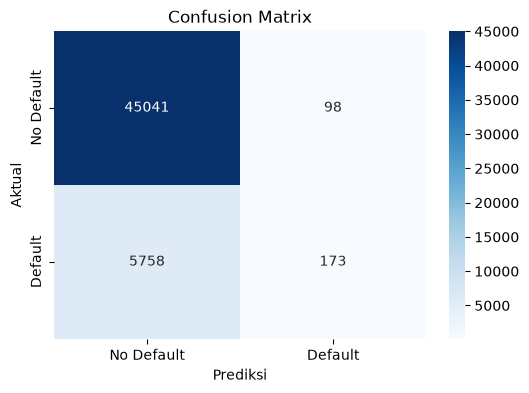

In [4]:
# Akurasi
accuracy = accuracy_score(y_test, y_pred)
print(f"Akurasi Model: {accuracy * 100:.2f}%\n")

# Classification Report
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['No Default (0)', 'Default (1)']))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Default', 'Default'], yticklabels=['No Default', 'Default'])
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Confusion Matrix')
plt.show()
